<a href="https://colab.research.google.com/github/shanmukhasrinivas02-tech/-iris-flower-classification./blob/main/Iris_Flower_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

print("Hello! My first Machine Learning project.")

print("Project: Iris Flower Classification")
print("Language: Python")
print("Goal: Predict Iris flower species")

Hello! My first Machine Learning project.
Project: Iris Flower Classification
Language: Python
Goal: Predict Iris flower species


In [ ]:

# Step 2: Import required libraries

import pandas as pd
import numpy as np

from sklearn.datasets import load_iris

# Load the Iris dataset
iris = load_iris()

# Convert dataset into a DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add flower species
df["species"] = iris.target

# Display the first 5 rows
print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   species  
0        0  
1        0  
2        0  
3        0  
4        0  


In [ ]:

# Step 3: Understand the dataset

# Check number of rows and columns
print("Dataset Shape:")
print(df.shape)

# Check column information
print("\nDataset Information:")
print(df.info())

# Check statistical summary
print("\nStatistical Summary:")
print(df.describe())

# Check flower species names
print("\nFlower Species:")
print(iris.target_names)

Dataset Shape:
(150, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB
None

Statistical Summary:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000     

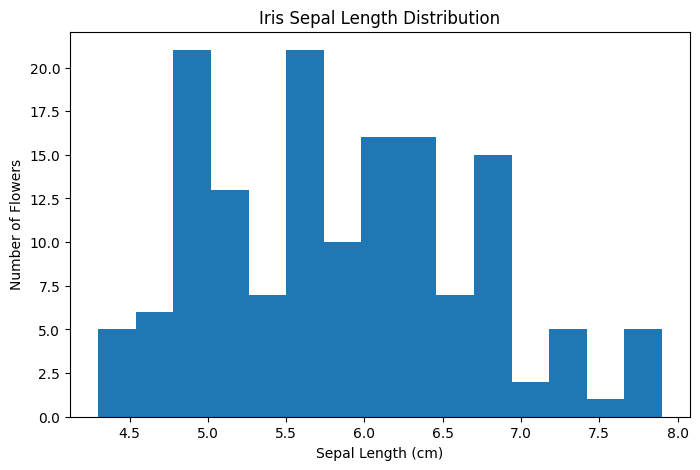

In [ ]:

import matplotlib.pyplot as plt

# Create a histogram
plt.figure(figsize=(8, 5))

plt.hist(df["sepal length (cm)"], bins=15)

plt.title("Iris Sepal Length Distribution")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Number of Flowers")

plt.show()

In [ ]:

# Step 5: Train a Machine Learning model

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Input features
X = df.drop("species", axis=1)

# Target output
y = df["species"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)

# Create the ML model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Machine Learning Model Trained Successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Machine Learning Model Trained Successfully!
Training samples: 120
Testing samples: 30


In [ ]:

# Step 6: Evaluate the ML model

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# Make predictions
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 90.0 %

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  2  8]]


In [ ]:

# Step 7: Test a new flower

new_flower = [[5.1, 3.5, 1.4, 0.2]]

prediction = model.predict(new_flower)

flower_name = iris.target_names[prediction[0]]

print("Predicted Flower:", flower_name)

Predicted Flower: setosa


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
